<a href="https://colab.research.google.com/github/Lapindodu/EMSE_labs/blob/main/PR_3_Zaitseva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

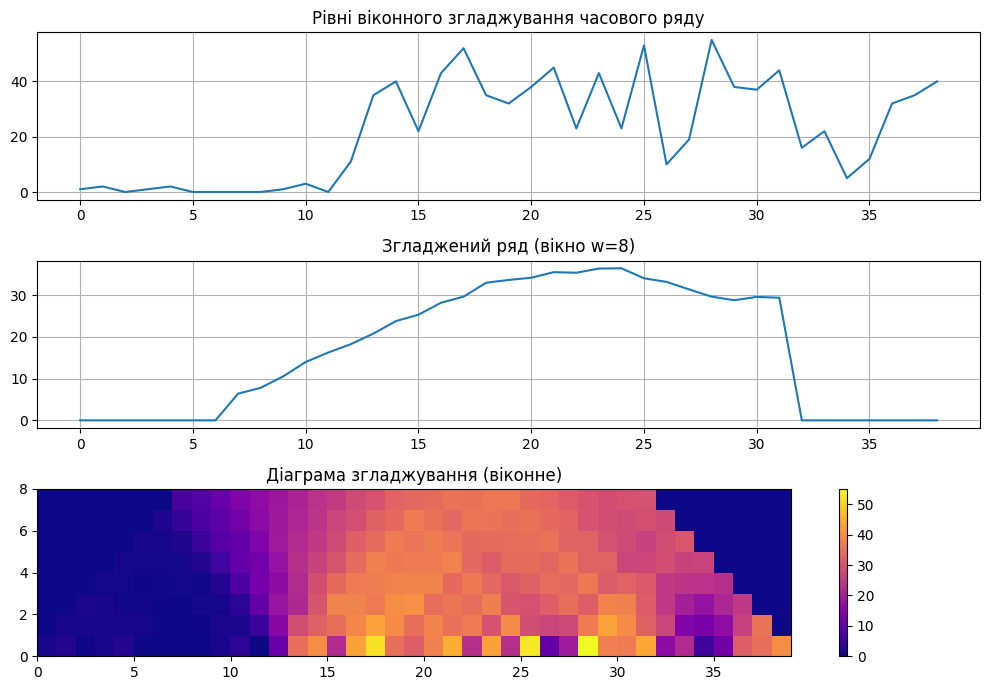

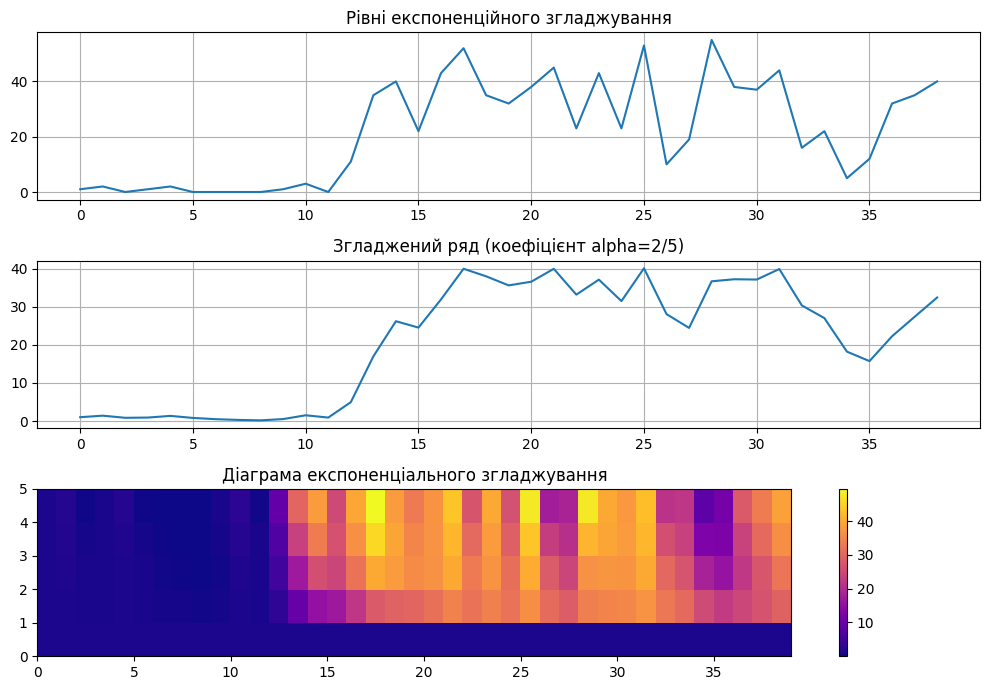

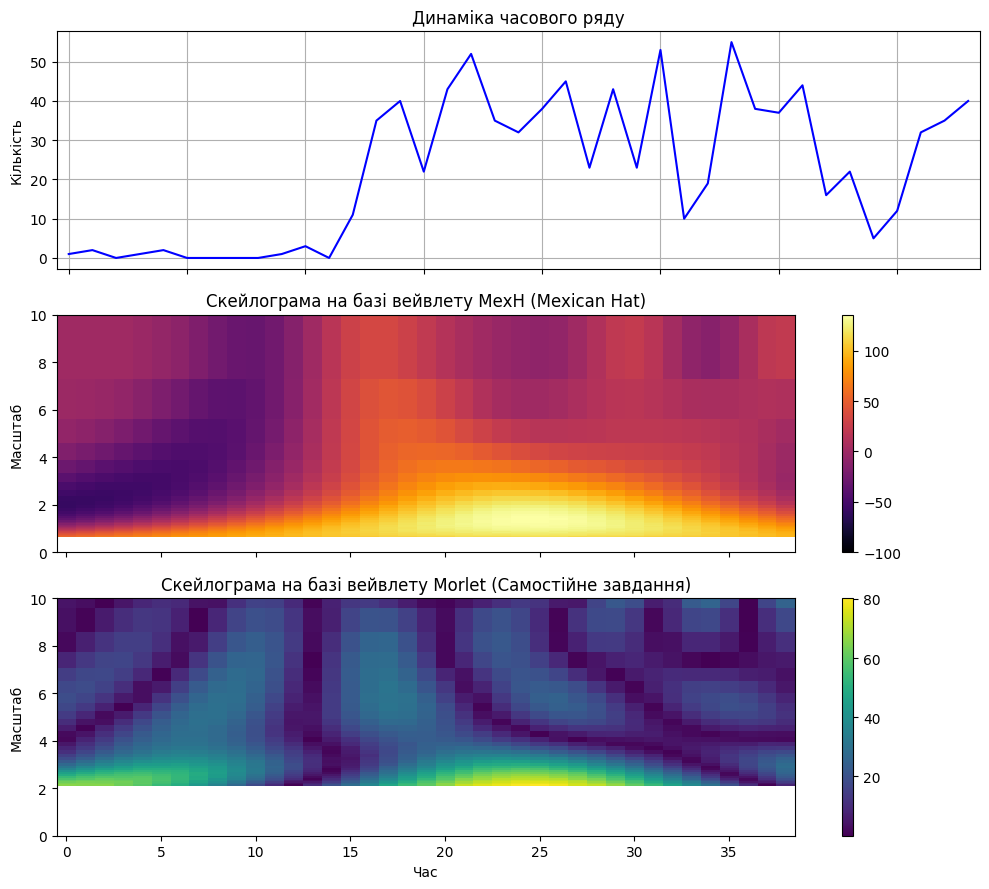

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pywt

D = [1, 2, 0, 1, 2, 0, 0, 0, 0, 1, 3, 0, 11, 35, 40, 22, 43, 52, 35, 32,
     38, 45, 23, 43, 23, 53, 10, 19, 55, 38, 37, 44, 16, 22, 5, 12, 32, 35, 40]

N = len(D)

M1 = 8
Z1 = np.zeros((M1, N))
C1 = list(D)

for j in range(M1):
    for k in range(j, N - j):
        sum_val = 0
        for l in range(1, j + 1):
            sum_val += D[k - l] + D[k + l]
        Z1[j][k] = (D[k] + sum_val) / (2 * j + 1)

fig1, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(10, 7))

ax0.plot(D)
ax0.set_title('Рівні віконного згладжування часового ряду')
ax0.grid(True)

for i in range(N):
    C1[i] = Z1[7][i]

ax1.plot(C1)
ax1.set_title('Згладжений ряд (вікно w=8)')
ax1.grid(True)

im1 = ax2.pcolor(Z1, cmap='plasma')
ax2.set_title('Діаграма згладжування (віконне)')
fig1.colorbar(im1, ax=ax2)

fig1.tight_layout()
plt.show()

M2 = 5
Z2 = np.zeros((M2, N))
C2 = list(D)

for j in range(M2):
    Z2[j][0] = D[0]

for j in range(M2):
    alf = j / M2
    for k in range(1, N):
        Z2[j][k] = D[k] * alf + Z2[j][k - 1] * (1 - alf)

fig2, (ax0_e, ax1_e, ax2_e) = plt.subplots(3, 1, figsize=(10, 7))

ax0_e.plot(D)
ax0_e.set_title('Рівні експоненційного згладжування')
ax0_e.grid(True)

for i in range(N):
    C2[i] = Z2[2][i]

ax1_e.plot(C2)
ax1_e.set_title('Згладжений ряд (коефіцієнт alpha=2/5)')
ax1_e.grid(True)

im2 = ax2_e.pcolor(Z2, cmap='plasma')
ax2_e.set_title('Діаграма експоненціального згладжування')
fig2.colorbar(im2, ax=ax2_e)

fig2.tight_layout()
plt.show()

fs = 100
t = range(N)

fig3, (ax_sig, ax_mexh, ax_morl) = plt.subplots(3, 1, sharex=True, figsize=(10, 9))

ax_sig.plot(t, D, color='blue')
ax_sig.grid(True)
ax_sig.set_ylabel("Кількість")
ax_sig.set_title("Динаміка часового ряду")

cwt_mexh, freqs_mexh = pywt.cwt(D, range(1, N), "mexh", sampling_period=1/fs)
im_mexh = ax_mexh.pcolormesh(t, freqs_mexh, cwt_mexh, vmin=-100, cmap="inferno")
ax_mexh.set_ylim(0, 10)
ax_mexh.set_ylabel("Масштаб")
ax_mexh.set_title("Скейлограма на базі вейвлету MexH (Mexican Hat)")
fig3.colorbar(im_mexh, ax=ax_mexh)

cwt_morl, freqs_morl = pywt.cwt(D, range(1, N), "morl", sampling_period=1/fs)
im_morl = ax_morl.pcolormesh(t, freqs_morl, np.abs(cwt_morl), cmap="viridis")
ax_morl.set_ylim(0, 10)
ax_morl.set_ylabel("Масштаб")
ax_morl.set_xlabel("Час")
ax_morl.set_title("Скейлограма на базі вейвлету Morlet (Самостійне завдання)")
fig3.colorbar(im_morl, ax=ax_morl)

fig3.tight_layout()
plt.show()